##### imports

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import shutil
import random

from scipy.stats import loguniform, uniform

from sklearn.model_selection import train_test_split,KFold,cross_val_score,RandomizedSearchCV
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline,Pipeline
from sklearn.metrics import (accuracy_score, precision_score,
                             f1_score,recall_score, roc_auc_score,
                             ConfusionMatrixDisplay, confusion_matrix,
                             classification_report)

### Data Loading

In [65]:
og_df=pd.read_csv("../../data/oc_risk50k_single_dataset.csv")

In [6]:
df = pd.read_csv("../data/non_invasive_df.csv")
print(df.shape)
df.head(5)

(50000, 12)


,Menopausal_Status,Oral_Contraceptive_History,Endometriosis_History,Tubal_Ligation_History,Family_History,Abdominal_Bloating,Pelvic_Pain,Early_Satiety,Urinary_Urgency,Unexplained_Weight_Loss,Ovarian_Cancer_Status,Risk_Category
0,1,1,0,0,0,1,0,0,0,0,0,0
1,1,0,0,0,1,0,1,1,1,1,1,1
2,1,0,0,0,1,1,1,0,0,0,1,2
3,1,0,0,0,0,1,0,0,0,0,1,2
4,1,1,0,1,1,0,0,0,0,0,0,0


In [11]:
target = "Risk_Category"

In [17]:
df[target].value_counts()

Risk_Category
0    24706
2    20411
1     4883
Name: count, dtype: int64

In [23]:
metrics_df = pd.DataFrame(index=["train_accuracy","test_accuracy","macro_precision",
                                 "macro_recall","macro_f1","macro_roc_auc"])

## Modelling

              precision    recall  f1-score   support

           0       0.88      0.91      0.90      4941
           1       0.14      0.29      0.19       977
           2       0.79      0.56      0.65      4082

    accuracy                           0.71     10000
   macro avg       0.60      0.59      0.58     10000
weighted avg       0.77      0.71      0.73     10000



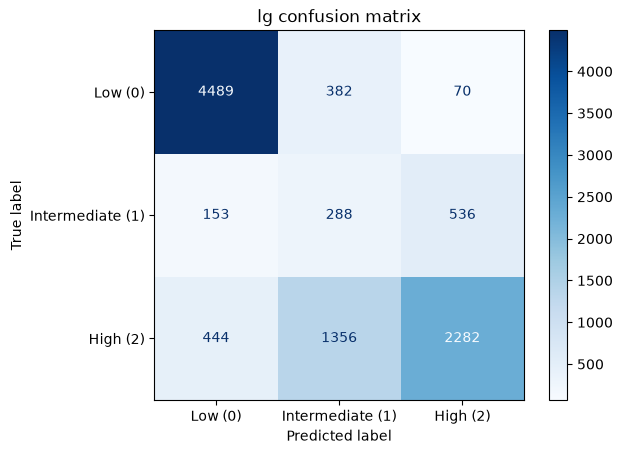



              precision    recall  f1-score   support

           0       0.87      0.91      0.89      4941
           1       0.16      0.26      0.20       977
           2       0.73      0.59      0.66      4082

    accuracy                           0.71     10000
   macro avg       0.59      0.59      0.58     10000
weighted avg       0.75      0.71      0.73     10000



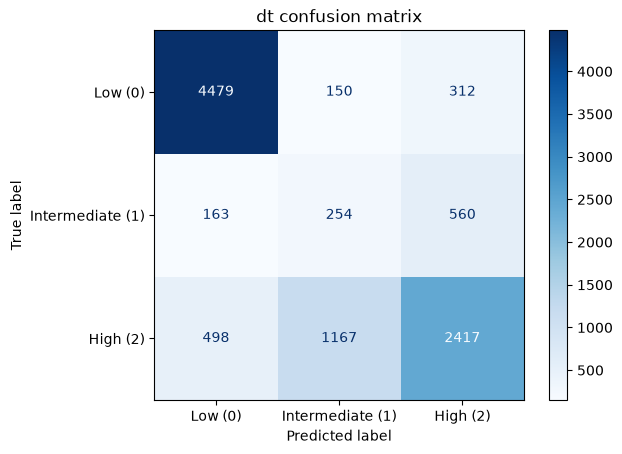

,non_inv_reduced_lg,non_inv_reduced_dt
train_accuracy,0.7056,0.7267
test_accuracy,0.7059,0.7150
macro_precision,0.6050,0.5893
macro_recall,0.5874,0.5862
macro_f1,0.7284,0.7262
macro_roc_auc,0.7948,0.7877


In [62]:
name = "non_inv_reduced"

x = df.drop(labels=[target,"Ovarian_Cancer_Status"],axis=1)
y = df[target]

x_train,x_test,y_train,y_test = train_test_split(x,y,train_size=0.8,stratify=y,random_state=1120)

models = {
    "lg": make_pipeline(
        #SimpleImputer(strategy='mean'),
        StandardScaler(),LogisticRegression(max_iter=5000,class_weight="balanced")),
    "dt": make_pipeline(
        #SimpleImputer(strategy='mean'),
        DecisionTreeClassifier(max_depth=7,random_state=1120,class_weight="balanced"))
}

for abbr, pipeline in models.items():
    pipeline.fit(x_train, y_train)
    y_pred = pipeline.predict(x_test)

    metrics_df[f"{name}_{abbr}"] = [
        round(accuracy_score(y_train, pipeline.predict(x_train)), 4),
        round(accuracy_score(y_test,y_pred),4),
        round(precision_score(y_test,y_pred,average="macro"),4),
        round(recall_score(y_test,y_pred,average="macro"),4),
        round(f1_score(y_test,y_pred,average="weighted"),4),
        round(roc_auc_score(y_test,pipeline.predict_proba(x_test),
                            multi_class="ovo",average="macro"),4)
    ]

    print(classification_report(y_test, y_pred))
    
# confusion matrix

    cm = confusion_matrix(y_test, y_pred)
    #print(cm)
    
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm, display_labels=["Low (0)","Intermediate (1)","High (2)"]
    )
    disp.plot(cmap=plt.cm.Blues)
    plt.title(f"{abbr} confusion matrix")
    plt.show()
    print("\n")


metrics_df

- does not predict (1) well
- probably leads to confusion with (2)

In [58]:
for col in df.columns[:-1]:
    print(f"{col.upper()}:")
    print(df.groupby(target)[col].mean())
    print()

MENOPAUSAL_STATUS:
Risk_Category
0    0.645309
1    0.838624
2    0.858312
Name: Menopausal_Status, dtype: float64

ORAL_CONTRACEPTIVE_HISTORY:
Risk_Category
0    0.516312
1    0.315994
2    0.299740
Name: Oral_Contraceptive_History, dtype: float64

ENDOMETRIOSIS_HISTORY:
Risk_Category
0    0.060390
1    0.177964
2    0.178237
Name: Endometriosis_History, dtype: float64

TUBAL_LIGATION_HISTORY:
Risk_Category
0    0.216911
1    0.084170
2    0.078291
Name: Tubal_Ligation_History, dtype: float64

FAMILY_HISTORY:
Risk_Category
0    0.078038
1    0.269711
2    0.283916
Name: Family_History, dtype: float64

ABDOMINAL_BLOATING:
Risk_Category
0    0.138914
1    0.680319
2    0.720396
Name: Abdominal_Bloating, dtype: float64

PELVIC_PAIN:
Risk_Category
0    0.122238
1    0.609052
2    0.642840
Name: Pelvic_Pain, dtype: float64

EARLY_SATIETY:
Risk_Category
0    0.080547
1    0.456072
2    0.479349
Name: Early_Satiety, dtype: float64

URINARY_URGENCY:
Risk_Category
0    0.152433
1    0.396887
2

In [ ]:
# Looking at variance + more columns

for col in df.columns[:-1]:
    print(f"{col.upper()}:")
    print(pd.DataFrame({"mean":og_df.groupby(target)[col].mean(),
                        "stdv":og_df.groupby(target)[col].std()})
         )
    print()

`Intermediate` and `High` Risk categories are too similar (with these features) to differentiate

In [158]:
og_cols=['Age', 'Menopausal_Status', 'Age_At_Menarche', 'Age_At_Menopause',
       'Family_History', 'BRCA1_Status', 'BRCA2_Status',
       'Lynch_Syndrome_Status', 'BMI', 'Parity', 'Oral_Contraceptive_History',
       'Oral_Contraceptive_Duration_Years', 'Endometriosis_History',
       'Hormone_Therapy_History', 'Tubal_Ligation_History',
       'Abdominal_Bloating', 'Pelvic_Pain', 'Early_Satiety', 'Urinary_Urgency',
       'Unexplained_Weight_Loss', 'CA125', 'HE4', 'CEA', 'CA19_9', 'AFP',
       'LDH', 'Hemoglobin', 'Platelet_Count', 'White_Blood_Cell_Count',
       'Albumin', 'C_Reactive_Protein', 'Tumor_Size', 'Laterality',
       'Tumor_Morphology', 'Solid_Component', 'Ascites_Status',
       'Bilateral_Mass', 'Papillary_Projection', 'Doppler_Vascularity',
       'Lymph_Node_Enlargement', 'Imaging_Risk_Score',
       'Charlson_Comorbidity_Index', 'ECOG_Performance_Status', 'Creatinine',
       'Liver_Enzyme_Level', 'Ovarian_Cancer_Status',"Treatment_Status","Time_To_Progression","Follow_Up_Status"]

In [160]:
features = [col for col in og_cols if col != target]

big_df = og_df.groupby(target)[features].agg(["mean", "std"])

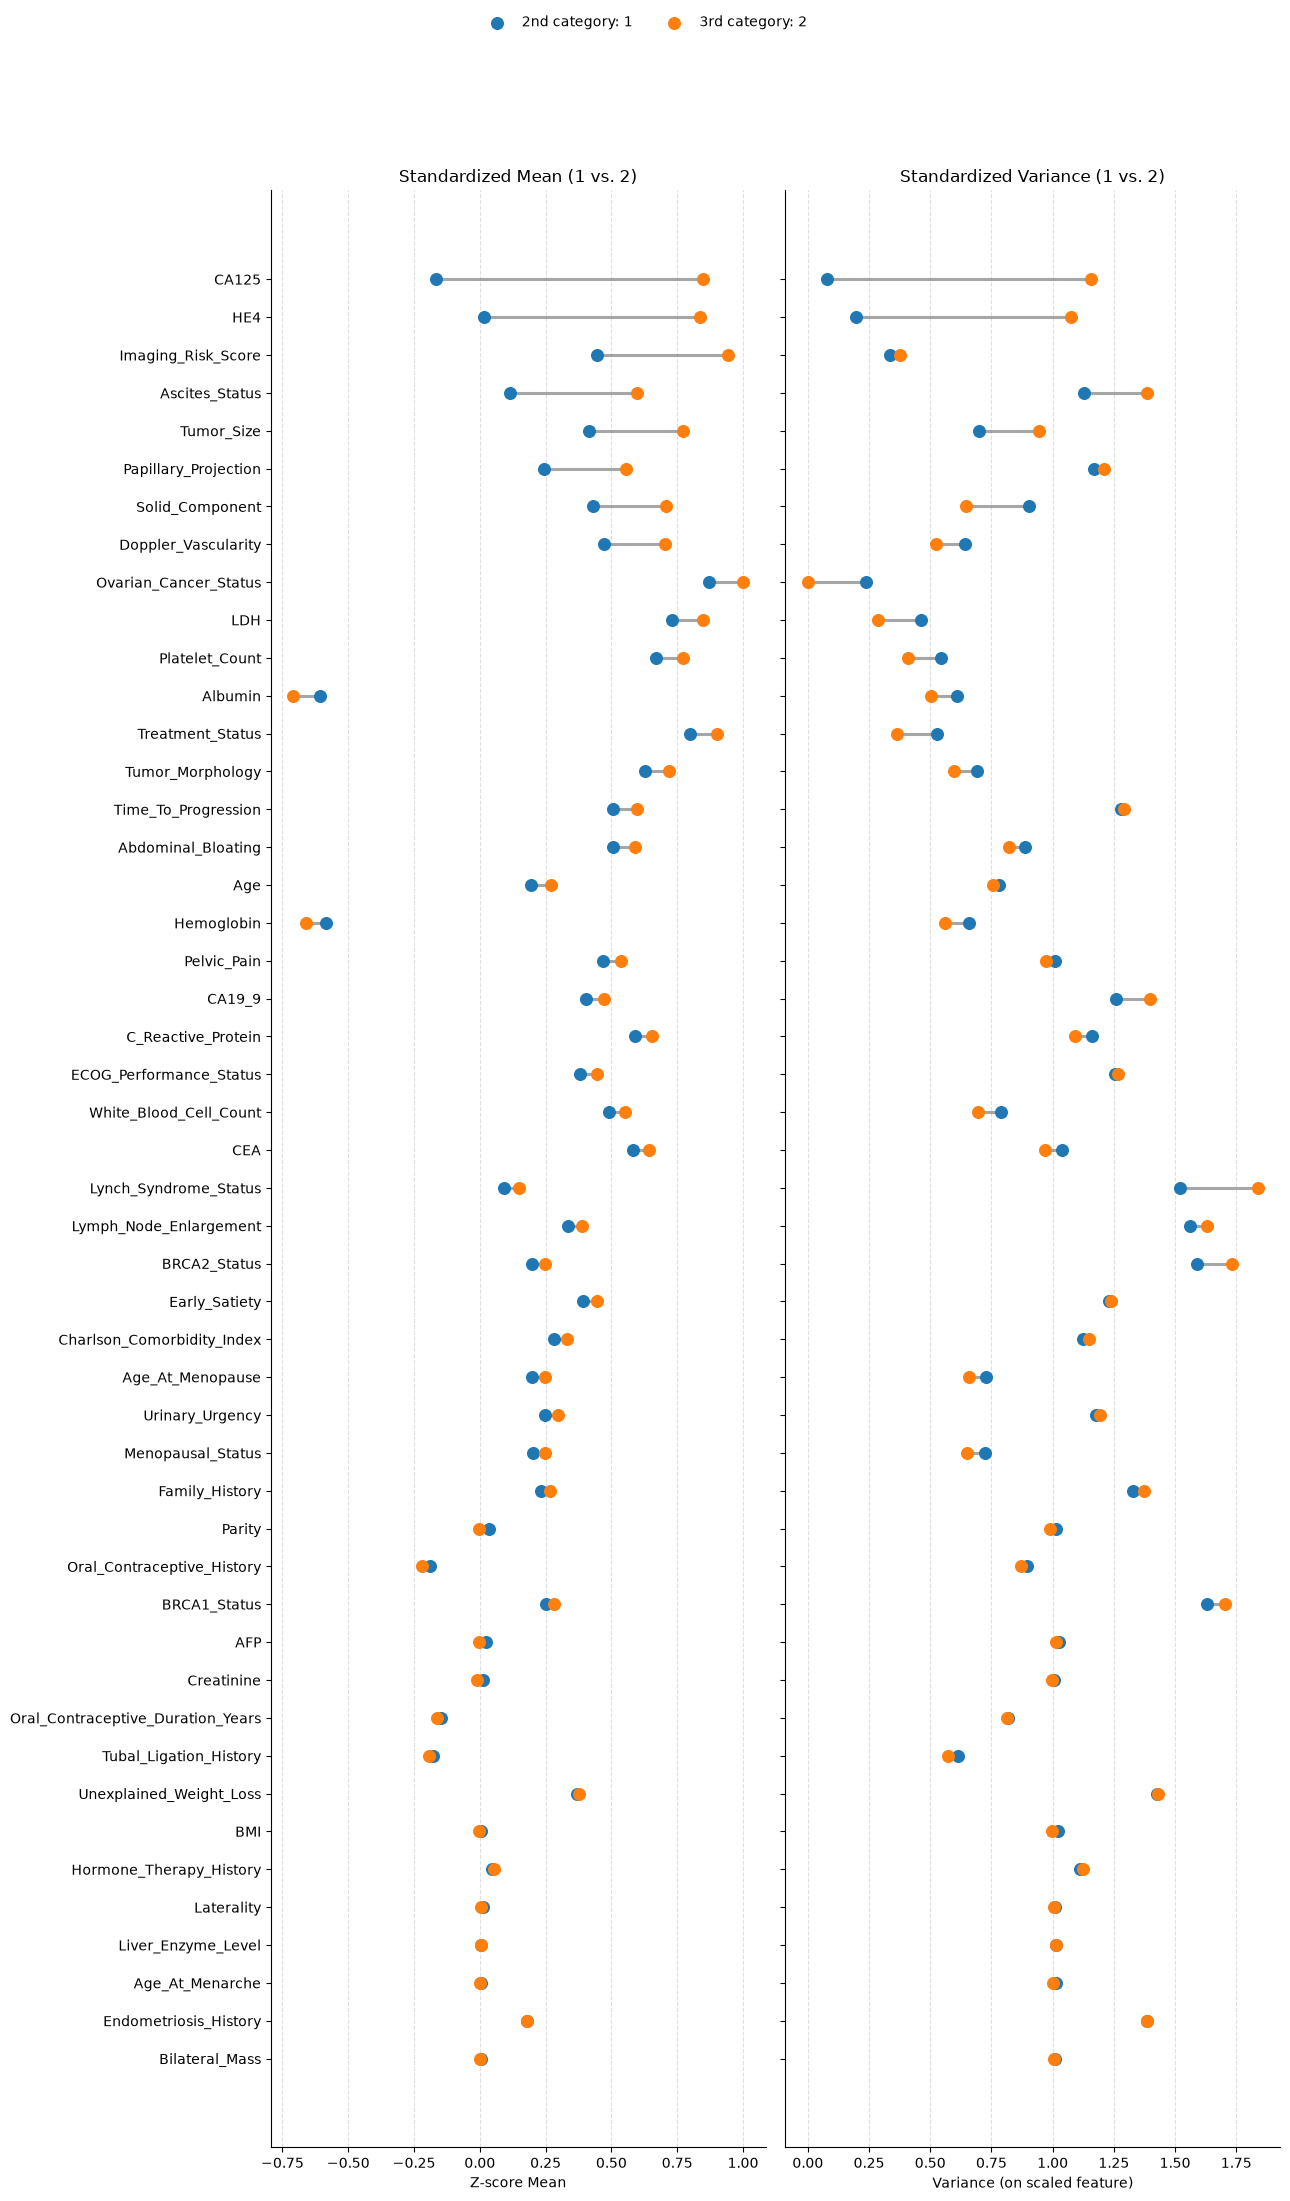

In [162]:
# 1. Feature columns (excluding target)
features = og_cols[:-1]

# 2. Pick the 2nd and 3rd unique categories in target
groups = og_df[target].dropna().unique()
cat_2, cat_3 = groups[1], groups[2]

sub_df = og_df[og_df[target].isin([cat_2, cat_3])]

# 1. Normalize features (choose StandardScaler or MinMaxScaler)
norm_df = og_df.copy()
scaler = StandardScaler()  # or MinMaxScaler()
norm_df[features] = scaler.fit_transform(norm_df[features])

# 2. Filter to 2nd and 3rd categories and compute mean & variance on scaled data
sub_df = norm_df[norm_df[target].isin([cat_2, cat_3])]
means = sub_df.groupby(target)[features].mean().loc[[cat_2, cat_3]].T
variances = sub_df.groupby(target)[features].var().loc[[cat_2, cat_3]].T

order = (means[cat_3] - means[cat_2]).abs().sort_values(ascending=True).index
means = means.loc[order]
variances = variances.loc[order]

# 3. Plot (reuses your existing plot_barbell helper)
fig, (ax_mean, ax_var) = plt.subplots(
    1, 2, figsize=(13, max(4, len(features) * 0.45)), sharey=True
)
plot_barbell(
    ax_mean,
    means,
    cat_2,
    cat_3,
    title=f"Standardized Mean ({cat_2} vs. {cat_3})",
    xlabel="Z-score Mean",
)
plot_barbell(
    ax_var,
    variances,
    cat_2,
    cat_3,
    title=f"Standardized Variance ({cat_2} vs. {cat_3})",
    xlabel="Variance (on scaled feature)",
)

handles, labels = ax_mean.get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc="upper center",
    ncol=2,
    frameon=False,
    bbox_to_anchor=(0.5, 1.02),
)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

In [155]:
big_df[["CA125","HE4","Ascites_Status","LDH"]]

CA125                     HE4             Ascites_Status  \
                     mean         std        mean         std           mean   
Risk_Category                                                                  
0               18.142369   12.471724   51.004902   28.950258       0.017850   
1               87.168738   38.178513  155.760460   65.646098       0.284661   
2              227.319932  148.131449  277.236131  153.286054       0.489736   

                                LDH             
                    std        mean        std  
Risk_Category                                   
0              0.132408  175.091010  34.651248  
1              0.451299  277.414499  44.239931  
2              0.499907  284.953873  34.877445

**Many of the few significantly differentiable columns are biomarkers